# 02 — Core Simulation Mapping
**CedarLight Energy Cooperative · Grid Load & Maintenance Planning Agent** — course topics 2 – 5 (+ reproducibility)

This notebook maps the agent's planning problems onto classic AI formulations and **benchmarks** them on a synthetic
environment: *inspection routing* (state-space search), *crew scheduling* (CSP) and *demand-spike response* (adversarial search).
Every experiment is seeded; all numbers below are produced by running the cells (not typed in).

**Run:** from the project root, `python -I 02_simulation/build_notebook.py` rebuilds this notebook, or open it in Jupyter and run all cells.
All data is synthetic; nothing here touches real grid systems.

### Hypotheses (recorded before running; evaluated in the scoreboard at the end)
| # | Hypothesis | Metric |
|---|---|---|
| H1 | UCS and A* return the optimal route (= brute-force optimum) on every instance | cost gap |
| H2 | A* with our heuristic expands fewer states than UCS | states expanded |
| H3 | BFS/IDS minimise *moves* but not *cost*; DFS is far from optimal | cost gap |
| H4 | Greedy best-first is cheapest to run but not always optimal | cost gap, expansions |
| H5 | MRV + forward checking cuts CSP search effort; all complete solvers agree on SAT/UNSAT | nodes, agreement |
| H6 | Min-conflicts solves most satisfiable instances but can never prove unsatisfiability | success rate |
| H7 | Alpha-beta returns exactly minimax's value and action with far fewer nodes | value equality, nodes |
| H8 | Expectimax has the lower *expected* cost; minimax has the lower *worst-case* cost | cost trade-off |
| H9 | Seeded runs are deterministic (stable agent outputs) | equality of repeated runs |

In [1]:
import sys, platform, subprocess
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("02_simulation").resolve()))
import sim_algos as S

CFG = {"seed": 42, "route_instances": 30, "csp_instances": 40, "csp_jobs": 8, "csp_blackout": 1, "game_horizons": [3, 4, 5]}
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__)
print("config:", CFG)

python 3.13.18 | numpy 2.5.3 | pandas 3.0.5
config: {'seed': 42, 'route_instances': 30, 'csp_instances': 40, 'csp_jobs': 8, 'csp_blackout': 1, 'game_horizons': [3, 4, 5]}


## Part A — Inspection routing as state-space search (topics 2 & 3)
**Formulation.** A crew starts at the depot (node 0) and must inspect every *required* asset, then return.
* **State:** `(location, set of assets still to inspect)`  **Initial:** `(depot, all required)`  **Goal:** `(depot, ∅)`
* **Actions / transitions:** drive along an edge; arriving at a still-uninspected required node removes it and adds an inspection cost.
* **Cost:** edge length + inspection time.
* **Heuristic:** `h = max over remaining r of [dist(loc,r) + dist(r,depot)] + inspect_cost × |remaining|` — the farthest site must still be reached and the crew must get home; every inspection must be paid.

    algorithm  cost  moves  expanded   ms
          BFS 22.87    7.0       153 0.17
          DFS 53.83   18.0        20 0.03
          UCS 22.31    7.0       151 0.25
          IDS 22.87    7.0       422 0.76
       Greedy 24.03    8.0        14 0.26
           A* 22.31    7.0        34 0.17
2-opt (local) 22.31    NaN        53 0.28
    Annealing 22.31    NaN       401 3.79
brute-force optimum over all visiting orders: 22.31


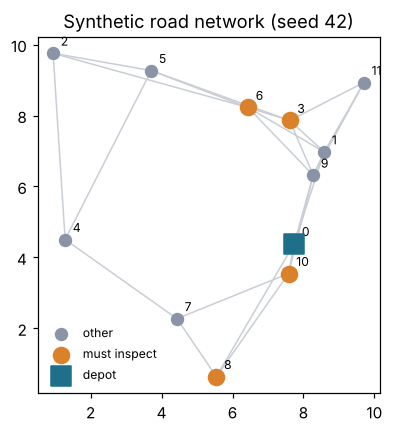

In [2]:
P = S.RouteProblem(seed=CFG["seed"])
algos = {"BFS": S.bfs, "DFS": S.dfs, "UCS": S.ucs, "IDS": S.ids, "Greedy": S.greedy, "A*": S.astar}
rows = []
for name, f in algos.items():
    r = f(P)
    rows.append(dict(algorithm=name, cost=round(r["cost"], 2), moves=r["moves"], expanded=r["expanded"], ms=round(r["ms"], 2)))
for name, r in (("2-opt (local)", S.two_opt(P, seed=CFG["seed"])), ("Annealing", S.anneal(P, seed=CFG["seed"]))):
    rows.append(dict(algorithm=name, cost=round(r["cost"], 2), moves=None, expanded=r["evals"], ms=round(r["ms"], 2)))
print(pd.DataFrame(rows).to_string(index=False))
print("brute-force optimum over all visiting orders:", round(S.brute_force_optimum(P), 2))

fig, ax = plt.subplots(figsize=(5.2, 4.2))
for a in P.adj:
    for b, _ in P.adj[a]:
        if a < b:
            ax.plot(*zip(P.pts[a], P.pts[b]), color="#c9ced6", lw=1, zorder=1)
ax.scatter(*P.pts.T, s=60, color="#8a94a6", zorder=2, label="other")
req = sorted(P.required)
ax.scatter(*P.pts[req].T, s=110, color="#d9822b", zorder=3, label="must inspect")
ax.scatter(*P.pts[0], s=170, marker="s", color="#1f6f8b", zorder=4, label="depot")
for i, (x, y) in enumerate(P.pts):
    ax.annotate(str(i), (x, y), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.set_title("Synthetic road network (seed %d)" % CFG["seed"]); ax.legend(frameon=False, fontsize=8); ax.set_aspect("equal")
plt.show()

### A.2 Benchmark across 30 random instances

               optimal_pct  mean_gap_pct  max_gap_pct  mean_moves  mean_expanded  mean_ms
algorithm                                                                                
BFS                  46.67          2.11        10.86        8.60         127.37     0.14
DFS                   0.00        101.34       241.87       19.63          24.03     0.02
UCS                 100.00          0.00         0.00        8.70         130.57     0.20
IDS                  46.67          2.11        10.86        8.60         755.83     1.28
Greedy               50.00          3.63        33.60        8.90          12.70     0.07
A*                  100.00          0.00         0.00        8.70          30.50     0.14
2-opt (local)       100.00          0.00         0.00         NaN          58.00     0.16
Annealing           100.00          0.00         0.00         NaN         401.00     3.94


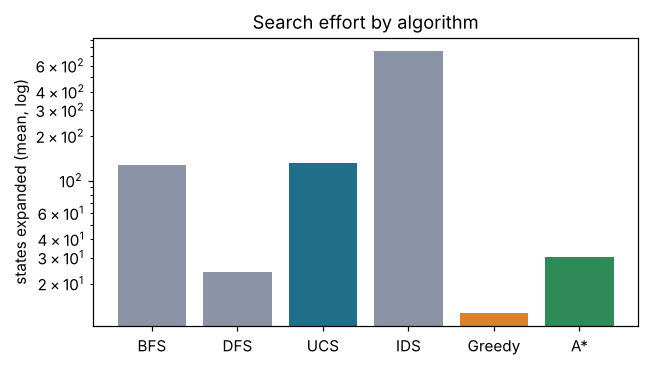

In [3]:
recs = []
for sd in range(CFG["route_instances"]):
    Pi = S.RouteProblem(seed=sd)
    opt = S.brute_force_optimum(Pi)
    for name, f in algos.items():
        r = f(Pi)
        recs.append(dict(seed=sd, algorithm=name, cost=r["cost"], moves=r["moves"], expanded=r["expanded"], ms=r["ms"], opt=opt))
    for name, r in (("2-opt (local)", S.two_opt(Pi, seed=sd)), ("Annealing", S.anneal(Pi, seed=sd))):
        recs.append(dict(seed=sd, algorithm=name, cost=r["cost"], moves=np.nan, expanded=r["evals"], ms=r["ms"], opt=opt))
route_df = pd.DataFrame(recs)
route_df["gap_pct"] = 100 * (route_df.cost - route_df.opt) / route_df.opt
route_df["is_opt"] = route_df.gap_pct.abs() < 1e-6
summary = route_df.groupby("algorithm").agg(optimal_pct=("is_opt", lambda x: 100 * x.mean()), mean_gap_pct=("gap_pct", "mean"),
                                            max_gap_pct=("gap_pct", "max"), mean_moves=("moves", "mean"),
                                            mean_expanded=("expanded", "mean"), mean_ms=("ms", "mean")).round(2)
print(summary.loc[["BFS", "DFS", "UCS", "IDS", "Greedy", "A*", "2-opt (local)", "Annealing"]].to_string())

fig, ax = plt.subplots(figsize=(6.4, 3.4))
order = ["BFS", "DFS", "UCS", "IDS", "Greedy", "A*"]
ax.bar(order, summary.loc[order, "mean_expanded"], color=["#8a94a6"] * 2 + ["#1f6f8b"] + ["#8a94a6"] + ["#d9822b", "#2e8b57"])
ax.set_yscale("log"); ax.set_ylabel("states expanded (mean, log)"); ax.set_title("Search effort by algorithm")
plt.show()

In [4]:
checks = [S.check_heuristic(S.RouteProblem(seed=sd)) for sd in range(CFG["route_instances"])]
print("instances checked:", len(checks), "| reachable states per instance (mean):", round(np.mean([c["states"] for c in checks]), 1))
print("admissible on all:", all(c["admissible"] for c in checks), "| consistent on all:", all(c["consistent"] for c in checks))

instances checked: 30 | reachable states per instance (mean): 139.1
admissible on all: True | consistent on all: True


### A.3 Does the picture change as the job gets bigger? (4, 6 and 8 required sites)

   ucs_expanded  astar_expanded  astar_optimal_pct  greedy_gap_pct  twoopt_gap_pct  anneal_gap_pct
k                                                                                                 
4         131.0            27.9              100.0            8.21            0.00            0.00
6         414.1            57.5              100.0           25.49            1.52            0.00
8        1170.2           130.1              100.0           25.02            0.00            0.01
Reading: with k=4 there are only 24 visiting orders, so local search looks perfect; the k=6 and k=8 rows are the fair test.


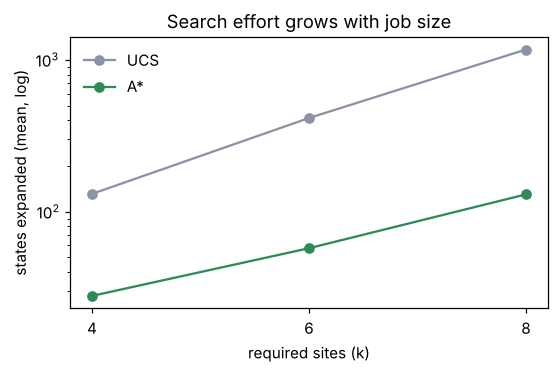

In [5]:
rows = []
for k in (4, 6, 8):
    for sd in range(10):
        Pk = S.RouteProblem(seed=100 + sd, k_required=k)
        u, a_, g = S.ucs(Pk), S.astar(Pk), S.greedy(Pk)
        t, an = S.two_opt(Pk, seed=sd, restarts=3), S.anneal(Pk, seed=sd)
        rows.append(dict(k=k, ucs_expanded=u["expanded"], astar_expanded=a_["expanded"], astar_is_optimal=abs(a_["cost"] - u["cost"]) < 1e-9,
                         greedy_gap_pct=100 * (g["cost"] - u["cost"]) / u["cost"], twoopt_gap_pct=100 * (t["cost"] - u["cost"]) / u["cost"],
                         anneal_gap_pct=100 * (an["cost"] - u["cost"]) / u["cost"]))
scale = pd.DataFrame(rows).groupby("k").agg(ucs_expanded=("ucs_expanded", "mean"), astar_expanded=("astar_expanded", "mean"),
                                           astar_optimal_pct=("astar_is_optimal", lambda x: 100 * x.mean()),
                                           greedy_gap_pct=("greedy_gap_pct", "mean"), twoopt_gap_pct=("twoopt_gap_pct", "mean"),
                                           anneal_gap_pct=("anneal_gap_pct", "mean")).round(2)
print(scale.to_string())
fig, ax = plt.subplots(figsize=(5.6, 3.2))
ax.plot(scale.index, scale.ucs_expanded, "o-", label="UCS", color="#8a94a6")
ax.plot(scale.index, scale.astar_expanded, "o-", label="A*", color="#2e8b57")
ax.set_yscale("log"); ax.set_xlabel("required sites (k)"); ax.set_ylabel("states expanded (mean, log)"); ax.legend(frameon=False)
ax.set_xticks([4, 6, 8]); ax.set_title("Search effort grows with job size"); plt.show()
print("Reading: with k=4 there are only 24 visiting orders, so local search looks perfect; the k=6 and k=8 rows are the fair test.")

**Why this matters for the agent.** UCS/A* give *provably optimal* inspection routes on small instances, so they are the default planner;
greedy and local search are fast fallbacks whose optimality gap is measured above and reported to the operator.

## Part B — Crew scheduling as a Constraint Satisfaction Problem (topic 5)
* **Variables:** inspection jobs. **Domains:** `(crew, slot)` pairs.
* **Unary:** the crew must have the job's skill; no outdoor work in storm-blackout slots.
* **Binary:** two jobs cannot share a `(crew, slot)`; jobs on the same feeder need ≥ 2 slots between them.
* **Global:** a crew performs at most 2 jobs per day (a day = 2 slots).

We compare plain backtracking against MRV, LCV, forward checking (FC) and AC-3 preprocessing, and against min-conflicts local search.
`nodes` counts value assignments attempted.

In [6]:
configs = {
    "plain":              dict(),
    "MRV":                dict(mrv=True),
    "MRV+FC":             dict(mrv=True, fc=True),
    "MRV+LCV+FC":         dict(mrv=True, lcv=True, fc=True),
    "AC3+MRV+LCV+FC":     dict(mrv=True, lcv=True, fc=True, use_ac3=True),
}
recs, mc_recs = [], []
for sd in range(CFG["csp_instances"]):
    Q = S.SchedProblem(sd, n_jobs=CFG["csp_jobs"], n_blackout=CFG["csp_blackout"])
    for name, kw in configs.items():
        r = S.solve_csp(Q, **kw)
        recs.append(dict(seed=sd, config=name, solved=r["solved"], nodes=r["nodes"], backtracks=r["backtracks"], timeout=r["timeout"], ms=r["ms"]))
    m = S.min_conflicts(Q, seed=sd)
    mc_recs.append(dict(seed=sd, solved=m["solved"], steps=m["steps"]))
csp_df, mc_df = pd.DataFrame(recs), pd.DataFrame(mc_recs)

sat = csp_df.pivot(index="seed", columns="config", values="solved")
agree = bool((sat.nunique(axis=1) == 1).all())
sat_seeds = sat.index[sat["plain"]].tolist()
print(f"instances: {CFG['csp_instances']} | satisfiable: {len(sat_seeds)} | unsatisfiable: {CFG['csp_instances'] - len(sat_seeds)}")
print("all complete solvers agree on SAT/UNSAT for every instance:", agree)
print("timeouts (hit the node limit) by config:", csp_df.groupby("config").timeout.sum().to_dict(),
      "-> timed-out runs are capped at the limit, so mean nodes for those configs are LOWER bounds")
csp_df["kind"] = csp_df.seed.map(lambda s: "SAT" if s in sat_seeds else "UNSAT")
tab = csp_df.groupby(["kind", "config"]).agg(mean_nodes=("nodes", "mean"), mean_backtracks=("backtracks", "mean"), mean_ms=("ms", "mean")).round(1)
print(tab.reindex(list(configs), level=1).to_string())

instances: 40 | satisfiable: 17 | unsatisfiable: 23
all complete solvers agree on SAT/UNSAT for every instance: True
timeouts (hit the node limit) by config: {'AC3+MRV+LCV+FC': 0, 'MRV': 1, 'MRV+FC': 0, 'MRV+LCV+FC': 0, 'plain': 2} -> timed-out runs are capped at the limit, so mean nodes for those configs are LOWER bounds
                      mean_nodes  mean_backtracks  mean_ms
kind  config                                              
SAT   plain                200.0            192.0      1.7
      MRV                  356.6            348.6      3.7
      MRV+FC                10.4              2.4      0.1
      MRV+LCV+FC             8.4              0.4      0.3
      AC3+MRV+LCV+FC         8.4              0.4      0.5
UNSAT plain              45562.1          45561.6    345.7
      MRV                32113.3          32113.0    332.3
      MRV+FC             11243.2          11243.2     52.8
      MRV+LCV+FC         11243.2          11243.2     75.4
      AC3+MRV+LCV+FC     11

min-conflicts on SAT instances:   solved 17/17  (mean steps when solved: 8)
min-conflicts on UNSAT instances: solved 0/23  (always exhausts 3000 steps; cannot prove infeasibility)

case study seed 0: blackout slots [5]; total domain size 75 -> 75 after AC-3
schedule valid (all constraints re-checked independently): True
          slot 0    slot 1    slot 2    slot 3    slot 4 slot 5 (BLACKOUT)
crew 0  J1[C,F2]  J3[C,F1]  J7[C,F0]  J4[B,F1]  J6[C,F0]                  
crew 1  J5[B,F0]  J0[A,F3]  J2[B,F2]                                      
crew 2                                                                    


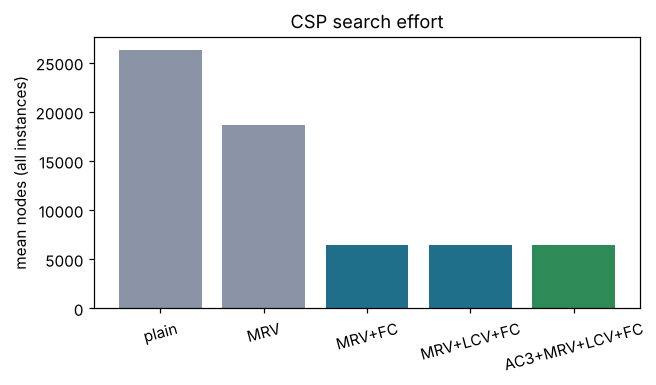

In [7]:
mc_sat = mc_df[mc_df.seed.isin(sat_seeds)]
mc_unsat = mc_df[~mc_df.seed.isin(sat_seeds)]
print(f"min-conflicts on SAT instances:   solved {int(mc_sat.solved.sum())}/{len(mc_sat)}  (mean steps when solved: {mc_sat[mc_sat.solved].steps.mean():.0f})")
print(f"min-conflicts on UNSAT instances: solved {int(mc_unsat.solved.sum())}/{len(mc_unsat)}  (always exhausts {mc_unsat.steps.max()} steps; cannot prove infeasibility)")

# Case study: one satisfiable instance, its AC-3 pruning and the resulting schedule
sd = sat_seeds[0]
Q = S.SchedProblem(sd, n_jobs=CFG["csp_jobs"], n_blackout=CFG["csp_blackout"])
doms = {v: list(Q.domain[v]) for v in Q.vars}
before = sum(len(d) for d in doms.values()); S.ac3(Q, doms); after = sum(len(d) for d in doms.values())
print(f"\ncase study seed {sd}: blackout slots {sorted(Q.blackout)}; total domain size {before} -> {after} after AC-3")
sol = S.solve_csp(Q, mrv=True, lcv=True, fc=True)["assign"]
print("schedule valid (all constraints re-checked independently):", Q.valid(sol))
grid = pd.DataFrame("", index=[f"crew {c}" for c in range(Q.n_crews)], columns=[f"slot {s}" + (" (BLACKOUT)" if s in Q.blackout else "") for s in range(Q.n_slots)])
for j, (c, s) in sorted(sol.items()):
    cell = f"J{j}[{Q.skill[j]},F{Q.feeder[j]}]"
    grid.iat[c, s] = (grid.iat[c, s] + " " + cell).strip()
print(grid.to_string())

fig, ax = plt.subplots(figsize=(6.4, 3.2))
g = csp_df.groupby("config").nodes.mean().reindex(list(configs))
ax.bar(g.index, g.values, color=["#8a94a6", "#8a94a6", "#1f6f8b", "#1f6f8b", "#2e8b57"])
ax.set_ylabel("mean nodes (all instances)"); ax.set_title("CSP search effort"); plt.xticks(rotation=15); plt.show()

### B.3 What did each technique actually buy?

In [8]:
red, ac3_unsat, trivial = [], 0, 0
for sd in range(CFG["csp_instances"]):
    Qi = S.SchedProblem(sd, n_jobs=CFG["csp_jobs"], n_blackout=CFG["csp_blackout"])
    d = {v: list(Qi.domain[v]) for v in Qi.vars}
    before_n = sum(map(len, d.values()))
    if S.ac3(Qi, d):
        red.append(before_n - sum(map(len, d.values())))
    else:
        ac3_unsat += 1
        trivial += any(not Qi.domain[v] for v in Qi.vars)
pruned = [r for r in red if r > 0]
print(f"AC-3 removed a value from the domains of {len(pruned)}/{CFG['csp_instances']} satisfiable-looking instances; it declared {ac3_unsat} instances unsatisfiable.")
print(f"  ...but in {trivial} of those {ac3_unsat} some job had an EMPTY initial domain (no crew has its skill), which MRV+FC also refutes with 0 nodes. So AC-3 added nothing beyond MRV+FC here.")
sat_nodes = csp_df[csp_df.kind == "SAT"].groupby("config").nodes.mean()
print(f"SAT instances, mean nodes: plain {sat_nodes['plain']:.0f} | MRV alone {sat_nodes['MRV']:.0f} | MRV+FC {sat_nodes['MRV+FC']:.1f} | +LCV {sat_nodes['MRV+LCV+FC']:.1f} | +AC-3 {sat_nodes['AC3+MRV+LCV+FC']:.1f}")
print("Reading: forward checking is what makes MRV useful (MRV alone sees only stale, unpruned domain sizes and can do worse than plain order);")
print("LCV helps a little on satisfiable instances and cannot help on unsatisfiable ones (every branch must be refuted anyway);")
print("AC-3 adds nothing here because our binary constraints are 'not equal' / clearance rules, which almost never leave a value without a supporting partner.")
print("Stronger propagation would need the global crew-day capacity and all-different reasoning built into the propagator.")

AC-3 removed a value from the domains of 0/40 satisfiable-looking instances; it declared 4 instances unsatisfiable.
  ...but in 4 of those 4 some job had an EMPTY initial domain (no crew has its skill), which MRV+FC also refutes with 0 nodes. So AC-3 added nothing beyond MRV+FC here.
SAT instances, mean nodes: plain 200 | MRV alone 357 | MRV+FC 10.4 | +LCV 8.4 | +AC-3 8.4
Reading: forward checking is what makes MRV useful (MRV alone sees only stale, unpruned domain sizes and can do worse than plain order);
LCV helps a little on satisfiable instances and cannot help on unsatisfiable ones (every branch must be refuted anyway);
AC-3 adds nothing here because our binary constraints are 'not equal' / clearance rules, which almost never leave a value without a supporting partner.
Stronger propagation would need the global crew-day capacity and all-different reasoning built into the propagator.


## Part C — Adversarial demand-spike game (topic 4)
Each hour the operator commits a **reserve level** (none / medium / high, with cost); then an **adversary** (nature) chooses a demand spike
(none / moderate / severe). Unserved demand is penalised; running *high* reserve two hours in a row only delivers reduced capacity (fatigue).
* **Minimax / alpha-beta** — plan against the worst-case spike (red-team / disturbance).
* **Expectimax** — plan against a probabilistic spike model (70 % none, 25 % moderate, 5 % severe).

Justification: the grid operator faces both a *risk-averse* objective (avoid worst-case unserved load) and an *expected-cost* objective;
the game lets us measure that trade-off explicitly instead of hiding it.

 horizon  minimax_value  alphabeta_value  same_value  same_action  minimax_nodes  alphabeta_nodes  pruned_pct  expectimax_value
       3           30.0             30.0        True         True           1639              431        73.7               8.7
       4           47.0             47.0        True         True          14761             2005        86.4              11.6
       5           55.0             55.0        True         True         132859             8603        93.5              14.5

policy comparison over horizon 4 (expected cost: 5000 random spike sequences from the probability model; worst case: all 81 sequences)
               expected_cost  worst_case_cost
never_reserve          26.40            168.0
minimax                18.53             47.0
expectimax             11.60             80.0


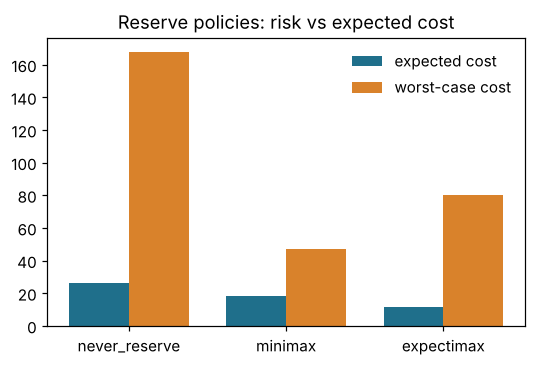

In [9]:
rows = []
for H in CFG["game_horizons"]:
    c1, c2, c3 = [0], [0], [0]
    mm, ab, ex = S.minimax(0, -1, H, c1), S.alphabeta(0, -1, H, c2), S.expectimax(0, -1, H, c3)
    rows.append(dict(horizon=H, minimax_value=mm[0], alphabeta_value=ab[0], same_value=mm[0] == ab[0], same_action=mm[1] == ab[1],
                     minimax_nodes=c1[0], alphabeta_nodes=c2[0], pruned_pct=round(100 * (1 - c2[0] / c1[0]), 1), expectimax_value=round(ex[0], 2)))
game_nodes = pd.DataFrame(rows)
print(game_nodes.to_string(index=False))

H = 4
game = S.evaluate_game(H=H, n_random=5000, seed=CFG["seed"])
game_df = pd.DataFrame(game).T.round(2)
print(f"\npolicy comparison over horizon {H} (expected cost: 5000 random spike sequences from the probability model; worst case: all 81 sequences)")
print(game_df.to_string())

fig, ax = plt.subplots(figsize=(5.6, 3.4))
x = np.arange(len(game_df)); w = 0.38
ax.bar(x - w / 2, game_df.expected_cost, w, label="expected cost", color="#1f6f8b")
ax.bar(x + w / 2, game_df.worst_case_cost, w, label="worst-case cost", color="#d9822b")
ax.set_xticks(x); ax.set_xticklabels(game_df.index); ax.legend(frameon=False); ax.set_title("Reserve policies: risk vs expected cost")
plt.show()

## Part D — Stabilising agent outputs (reproducibility)
Every generator and solver takes an explicit seed. We re-run the three experiments from scratch and compare the *decision-relevant* outputs
(costs, nodes, schedules, policy values — not wall-clock time).

In [10]:
def fingerprint():
    out = {}
    P0 = S.RouteProblem(seed=7)
    out["route"] = {n: (round(f(P0)["cost"], 9), f(P0)["expanded"]) for n, f in algos.items()}
    Q0 = S.SchedProblem(3, n_jobs=8, n_blackout=1)
    r = S.solve_csp(Q0, mrv=True, lcv=True, fc=True)
    out["csp"] = (r["solved"], r["nodes"], sorted(r["assign"].items()) if r["assign"] else None)
    out["mc"] = S.min_conflicts(Q0, seed=3)["steps"]
    c = [0]; out["game"] = (S.minimax(0, -1, 4, c), c[0], S.evaluate_game(H=3, n_random=500, seed=1))
    return out
a, b = fingerprint(), fingerprint()
print("two independent runs identical:", a == b)

two independent runs identical: True


## Part E — Integration check across modules
The simulation is only one piece. This cell runs the unit/evaluation tests of the logic (`03_logic`), uncertainty (`04_uncertainty`) and ML (`05_ml`) modules,
and reads the saved ML metrics, so the notebook is an end-to-end evidence index.

In [11]:
import json
targets = [p for p in ("02_simulation", "03_logic", "04_uncertainty", "05_ml", "tests") if Path(p).exists()]
print("test folders:", targets)
res = subprocess.run([sys.executable, "-I", "-m", "pytest", *targets, "-q", "--no-header", "-p", "no:cacheprovider"],
                     capture_output=True, text=True)
print((res.stdout.strip().splitlines() or ["(no output)"])[-1])
mp = Path("05_ml/artifacts/metrics.json")
if mp.exists():
    m = json.loads(mp.read_text())
    f = m["forecast"]
    print(f"forecast ({f['selected']}): test MAE {f['results'][f['selected']]['test']['mae']:.1f} kW vs persistence {f['results']['persistence_24h']['test']['mae']:.1f} kW; "
          f"90% interval test coverage {f['interval']['test_coverage']:.1%}")
    c = m["failure"]; sel = c["selected"]
    print(f"failure model ({sel}): test AUC {c['results'][sel]['test']['auc']:.3f}, Brier {c['results'][sel]['test']['brier']:.3f}")
    r = m["rl"]; print(f"Q-learning reward {r['q_learning']['mean_reward']:.2f} vs greedy {r['greedy_threshold']['mean_reward']:.2f}; safety violations {r['q_learning']['safety_violations']}")
else:
    print("05_ml metrics not found; run 05_ml/run_ml.py")

test folders: ['02_simulation', '03_logic', '04_uncertainty', '05_ml', 'tests']
184 passed, 1 skipped in 72.79s (0:01:12)
forecast (hgb): test MAE 15.5 kW vs persistence 26.3 kW; 90% interval test coverage 87.2%
failure model (logreg): test AUC 0.777, Brier 0.066
Q-learning reward -6.53 vs greedy -6.56; safety violations 0


## Hypothesis scoreboard (computed from the results above)

In [12]:
sm = summary
def has(cond): return "SUPPORTED" if cond else "NOT SUPPORTED"
non_bfs = route_df[route_df.algorithm == "BFS"]
H = {}
H["H1"] = has(sm.loc["UCS", "optimal_pct"] == 100 and sm.loc["A*", "optimal_pct"] == 100)
H["H2"] = has(sm.loc["A*", "mean_expanded"] < sm.loc["UCS", "mean_expanded"])
H["H3"] = has(sm.loc["BFS", "optimal_pct"] < 100 and sm.loc["IDS", "mean_moves"] <= sm.loc["BFS", "mean_moves"] + 1e-9 and sm.loc["DFS", "mean_gap_pct"] > 20)
H["H4"] = has(sm.loc["Greedy", "mean_expanded"] < sm.loc["A*", "mean_expanded"] and sm.loc["Greedy", "optimal_pct"] < 100)
H["H5"] = has(agree and csp_df[csp_df.config == "MRV+FC"].nodes.mean() < csp_df[csp_df.config == "plain"].nodes.mean())
H["H6"] = has(len(mc_sat) > 0 and mc_sat.solved.mean() >= 0.5 and mc_unsat.solved.sum() == 0)
H["H7"] = has(bool(game_nodes.same_value.all() and game_nodes.same_action.all() and (game_nodes.alphabeta_nodes < 0.5 * game_nodes.minimax_nodes).all()))
H["H8"] = has(game_df.loc["expectimax", "expected_cost"] < game_df.loc["minimax", "expected_cost"] and game_df.loc["minimax", "worst_case_cost"] < game_df.loc["expectimax", "worst_case_cost"])
H["H9"] = has(a == b)
for k, v in H.items(): print(k, v)

print()
print(f"A* expands {sm.loc['A*','mean_expanded']:.0f} states vs UCS {sm.loc['UCS','mean_expanded']:.0f} (x{sm.loc['UCS','mean_expanded']/sm.loc['A*','mean_expanded']:.1f} fewer); greedy is optimal on {sm.loc['Greedy','optimal_pct']:.0f}% of instances (worst gap {sm.loc['Greedy','max_gap_pct']:.1f}%).")
print(f"BFS is optimal on {sm.loc['BFS','optimal_pct']:.0f}% of instances; DFS mean gap {sm.loc['DFS','mean_gap_pct']:.0f}%. 2-opt optimal on {sm.loc['2-opt (local)','optimal_pct']:.0f}%, annealing on {sm.loc['Annealing','optimal_pct']:.0f}%.")
print(f"CSP: MRV+FC mean nodes {csp_df[csp_df.config=='MRV+FC'].nodes.mean():.0f} vs plain {csp_df[csp_df.config=='plain'].nodes.mean():.0f}; min-conflicts solved {mc_sat.solved.mean():.0%} of satisfiable instances.")
print(f"Game: alpha-beta prunes {game_nodes.pruned_pct.iloc[-1]:.0f}% of nodes at horizon {game_nodes.horizon.iloc[-1]}; expectimax cuts expected cost {game_df.loc['minimax','expected_cost']:.1f} -> {game_df.loc['expectimax','expected_cost']:.1f} but its worst case rises {game_df.loc['minimax','worst_case_cost']:.0f} -> {game_df.loc['expectimax','worst_case_cost']:.0f}.")

H1 SUPPORTED
H2 SUPPORTED
H3 SUPPORTED
H4 SUPPORTED
H5 SUPPORTED
H6 SUPPORTED
H7 SUPPORTED
H8 SUPPORTED
H9 SUPPORTED

A* expands 30 states vs UCS 131 (x4.3 fewer); greedy is optimal on 50% of instances (worst gap 33.6%).
BFS is optimal on 47% of instances; DFS mean gap 101%. 2-opt optimal on 100%, annealing on 100%.
CSP: MRV+FC mean nodes 6469 vs plain 26283; min-conflicts solved 100% of satisfiable instances.
Game: alpha-beta prunes 94% of nodes at horizon 5; expectimax cuts expected cost 18.5 -> 11.6 but its worst case rises 47 -> 80.


## Failure log (defects found while building and benchmarking, with the fix and the guard that prevents recurrence)
| # | Where | What went wrong | Fix | Guard |
|---|---|---|---|---|
| 1 | `03_logic` entailment | A rule literal with no constants (`CriticalLoad(?c)`) matched any fact, so `ImpactHigh(Hosp1)` was *uncertain* instead of *unknown* | Count only literals anchored to the query's constants | `test_transitive_impact_high` |
| 2 | `04_uncertainty` decision rule | Margin-based confidence escalated clearly low-risk assets (3.5 % failure chance) | Confidence measured against the break-even probability | `test_clearly_low_risk_defers_not_escalates` |
| 3 | `05_ml` data generator | Failures were never repaired → failure rate drifted 8 % → 37 %, making evaluation meaningless | Trailing-12-month fault history, repair bonus, burn-in | base-rate checks; model card §2 |
| 4 | `05_ml` Q-learning | State omitted position in the day → performed no better than never inspecting | Added position to the state; verified against exact dynamic programming | `test_trained_policy_has_no_violations_and_beats_naive` |
| 5 | `05_ml` logistic regression | `class_weight="balanced"` inflated probabilities consumed by the decision rule (Brier 0.153 vs 0.066) | Unweighted model | `test_selected_failure_model_probabilities_are_usable` |
| 6 | `02_simulation` alpha-beta | Bounds were passed to children without the accumulated cost, so nothing was pruned (equal node counts) | Carry accumulated path cost; bounds apply to total cost | H7 + `test_alphabeta_matches_minimax_and_prunes` |
| 7 | `02_simulation` CSP | First instance family was *entirely unsatisfiable*, so ablations looked identical; MRV used re-computed legal counts, hiding forward checking's benefit | Tuned instance generator to ~40 % satisfiable; MRV uses the *current pruned* domain | H5 / H6 above |

### Known limitations
* Instances are small (a few thousand search states at most, 8 jobs) so exact solvers dominate; real networks would need heuristics/decomposition. Timed-out CSP runs (see B.1) make some mean node counts lower bounds.
* The CSP treats crew-day capacity as a checked global constraint, not a propagated one (AC-3 handles only binary constraints).
* The game is a stylised one-resource model; probabilities and costs are synthetic.
* Wall-clock times are indicative only (single machine, no repetition).

### What feeds the agent
Routing → `actions.py` (`rank_inspections` tour order) · CSP → `policy.py`/`actions.py` (`propose_schedule` feasibility) · Game → risk-aware reserve recommendation shown with both expected and worst-case cost.